# 07 — Teacher–Student tuần 7: baseline, nghiên cứu KD và kết luận

Phụ trách: Phúc. Notebook duy nhất cho tuần 7, đã gộp baseline và các thử nghiệm.
Đọc theo thứ tự: **A. LR cơ bản → B. khảo sát thuật toán → C. LightGBM Group CV → D. phân tích KD → E. quyết định Teacher.**

- A minh họa trực tiếp cách train hai LR nhỏ, không ghi đè artifact.
- B/C đọc các thí nghiệm đã lưu; Run All không chạy lại benchmark 30/36 fits.
- Toàn bộ số liệu là development/Train CV, không phải Official Test hoặc bằng chứng production.
- Teacher v2 và artifacts lịch sử giữ nguyên. Student chưa là model mặc định.
- Các script tái lập: train_student.py, compare_students.py, train_lightgbm_student.py;
  summarize_student_comparison.py chỉ tạo báo cáo/đóng gói/fixtures từ kết quả có sẵn.


## A. Baseline LR: flow train


In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from scipy.sparse import vstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "scripts"))
from train_student import load_data
from phishguard_vn.student import metrics, choose_threshold, load_student

config = json.loads((ROOT / "configs/week7_student.json").read_text(encoding="utf-8"))
train, val, excluded = load_data(ROOT)
pd.DataFrame({"split": ["Train", "Validation"],
              "rows": [len(train), len(val)],
              "phishing": [train.target.sum(), val.target.sum()]})

,split,rows,phishing
0,Train,13078,2074
1,Validation,1585,24


## 1. Teacher targets là gì?

Teacher đã dự đoán trên các mẫu Train. Ta chỉ lấy file theo ID, không fit Teacher ở notebook.
`target` là nhãn thật; `teacher_score` là score chưa calibrated.
Bản KD học q = (1-alpha)*nhãn thật + alpha*score Teacher. Teacher đã thấy Train nên đây là
targets in-sample, không phải OOF. Validation không tham gia fitting.

In [2]:
targets = pd.read_csv(ROOT / "artifacts/student_week7/teacher_targets.csv.gz")
targets = train[["id"]].merge(targets, on="id", validate="one_to_one")
assert targets.id.tolist() == train.id.tolist()
assert len(targets) == len(train)
targets.head()  # Chỉ có ID/nhãn/score, không chứa URL thật

,id,target,teacher_score,teacher_label,kd_target
0,0004e6cc-1580-503e-8ac9-b8039a0ebee9,0,0.015480,0,0.007740
1,00091f3e-1d47-52cb-b645-2a4c91788ba0,0,0.004145,0,0.002072
2,000c7930-c2e6-52c8-aee2-1cd639aadfc4,0,0.001806,0,0.000903
3,000f5203-2e84-50ed-b16b-738c5d96c199,0,0.000345,0,0.000172
4,001277ac-004d-5d93-9e5c-b718397e5ddd,0,0.024184,0,0.012092


## 2. Từ URL thành số bằng TF-IDF ký tự

`train.text` là URL đã canonicalize. Tách các đoạn 3–5 ký tự, chọn tối đa 8.192 cột.
Vocabulary và IDF chỉ học từ Train; Validation chỉ transform.
Hai cách học dùng chung ma trận để so sánh công bằng.

In [3]:
vectorizer = TfidfVectorizer(
    analyzer="char", ngram_range=tuple(config["ngram_range"]),
    min_df=config["min_df"], max_features=config["max_features"],
    lowercase=False, sublinear_tf=True, norm="l2",
)
X_train = vectorizer.fit_transform(train.text)
X_val = vectorizer.transform(val.text)
print("Train:", X_train.shape, "Validation:", X_val.shape)

Train: (13078, 8192) Validation: (1585, 8192)


## 3. Gọi mô hình và train trực tiếp

Với mỗi mẫu: bản nhãn 1 có trọng số q, bản nhãn 0 có trọng số 1-q.
Nếu q là 0/1 thì tương đương học nhãn thật. Nếu q nằm giữa 0 và 1 thì mô hình học mục tiêu mềm.
Tổng trọng số mỗi mẫu luôn bằng 1. Hai bản cùng C, solver, seed và vocabulary.

In [4]:
results = []
for name in ("hard_only", "kd_mixed"):
    q = train.target.to_numpy() if name == "hard_only" else targets.kd_target.to_numpy()
    model = LogisticRegression(
        C=config["C"], solver="liblinear",
        max_iter=config["max_iter"], random_state=config["seed"],
    )
    model.fit(
        vstack([X_train, X_train]),
        np.r_[np.ones(len(q)), np.zeros(len(q))],
        sample_weight=np.r_[q, 1-q],
    )
    score = model.predict_proba(X_val)[:, 1]
    threshold = choose_threshold(val.target, score, config["fpr_budget"])
    results.append({"candidate": name, **metrics(val.target, score, threshold)})
pd.DataFrame(results)

,candidate,ap,precision,recall,f1,fpr,tp,fp,tn,fn,threshold
0,hard_only,0.292578,0.363636,0.333333,0.347826,0.008969,8,14,1547,16,0.548606
1,kd_mixed,0.304568,0.380952,0.333333,0.355556,0.008328,8,13,1548,16,0.564856


## 4. Đọc kết quả đúng phạm vi

Validation được dùng chọn model/ngưỡng, nên bảng trên không phải final performance độc lập.
Chỉ có 24 phishing trong Validation. So thêm với Teacher đã phát hành; agreement cao có thể
đến từ đa số benign. Không chạy Official Test hoặc external ở notebook này.

In [5]:
teacher = json.loads((ROOT / "reports/tables/student_week7/teacher_validation.json").read_text(encoding="utf-8"))
pd.DataFrame([teacher, *results])

,candidate,ap,precision,recall,f1,fpr,tp,fp,tn,fn,threshold
0,released_teacher_v2,0.554910,0.517241,0.625000,0.566038,0.008969,15,14,1547,9,0.694574
1,hard_only,0.292578,0.363636,0.333333,0.347826,0.008969,8,14,1547,16,0.548606
2,kd_mixed,0.304568,0.380952,0.333333,0.355556,0.008328,8,13,1548,16,0.564856


## B. Khảo sát Validation ban đầu: so sánh thuật toán

Các AP trong phần này thuộc khảo sát Validation lịch sử; phần C dùng Group CV. Candidate đứng đầu menu không phải engine cuối.


In [6]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from phishguard_vn.student_comparison import load_comparison_student
TABLES = ROOT / "reports/tables/student_comparison"
FIGURES = ROOT / "reports/figures/student_comparison"
manifest = json.loads((ROOT / "artifacts/student_comparison/manifest.json").read_text(encoding="utf-8"))
plan = manifest["plan"]
summary = pd.read_csv(TABLES / "summary.csv")
runs = pd.read_csv(TABLES / "runs.csv")
print("Train:", manifest["train_rows"], "Validation:", manifest["validation_rows"],
      "phishing Validation:", manifest["validation_positives"])
print("Fits:", len(runs) // 2, "(mỗi fit được báo tại hai operating points)")
print("Source revision:", manifest["producer_revision"], "source dirty:", manifest["producer_source_dirty"])

Train: 13078 Validation: 1585 phishing Validation: 24
Fits: 30 (mỗi fit được báo tại hai operating points)
Source revision: 5ae16575db6725a44ff22ee73cb1721a68c422e6 source dirty: False


## 1. Vì sao thử các họ này?

Cần phân biệt **đổi input** với **đổi thuật toán**:
- text LR là mốc cũ đọc ký tự.
- E2 LR kiểm tra đầu vào E2 có tín hiệu khác gì.
- MLP/HistGB/Extra Trees cùng nhận 20 E2, để so tác dụng phi tuyến.
- Trong mỗi họ, hard-only và KD có cùng cấu trúc/ngân sách; đó mới là đối chiếu lợi ích KD.

Không thử tất cả thuật toán. Menu, cấu hình, 3 seed và tiêu chí được chốt trước fitting.

In [7]:
pd.DataFrame([
    {"family": name, "input": item["representation"], "algorithm": item["algorithm"],
     "hypothesis": item["reason"]}
    for name, item in plan["families"].items()
])

,family,input,algorithm,hypothesis
0,text_lr,char_tfidf_8192,LogisticRegression,Existing compact lexical baseline.
1,e2_lr,frozen_e2_20,LogisticRegression,Input control: distinguish E2 signal from algo...
2,e2_mlp,frozen_e2_20,MLPClassifier,Small nonlinear model; standardized Train-only...
3,e2_hist,frozen_e2_20,HistGradientBoostingClassifier,Compact single boosting model approximates E2 ...
4,e2_extra,frozen_e2_20,ExtraTreesClassifier,Randomized nonlinear tree ensemble as a differ...


## 2. Mô hình được gọi trực tiếp thế nào?

Ví dụ các constructor đúng cấu hình đã chạy. Vòng train thực tế nằm trong
`scripts/compare_students.py`: chuẩn hóa nếu cần → tạo weighted copies → `model.fit(X, y, sample_weight=w)`.
MLP dùng StandardScaler fit Train; cây dùng E2 gốc. Không có framework tự chọn model ẩn.

In [8]:
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, ExtraTreesClassifier

mlp = MLPClassifier(hidden_layer_sizes=(32, 16), activation="relu",
    max_iter=200, early_stopping=False, n_iter_no_change=201, tol=0,
    alpha=0.001, learning_rate_init=0.001, random_state=42)
hist = HistGradientBoostingClassifier(max_iter=150, max_leaf_nodes=7,
    learning_rate=0.05, min_samples_leaf=30, l2_regularization=1,
    early_stopping=False, random_state=42)
extra = ExtraTreesClassifier(n_estimators=64, max_depth=8,
    min_samples_leaf=5, random_state=42, n_jobs=1)
display(mlp, hist, extra)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(32, ...)"
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.001
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"tol tol: float, default=1e-4Tolerance for the optimization. When the loss or score is not improvingby at least ``tol`` for ``n_iter_no_change`` consecutive iterations,unless ``learning_rate`` is set to 'adaptive', convergence isconsidered to be reached and training stops.",0
,"n_iter_no_change n_iter_no_change: int, default=10Maximum number of epochs to not meet ``tol`` improvement.Only effective when solver='sgd' or 'adam'... versionadded:: 0.20",201
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5


,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.05
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",150
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",7
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",30
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",1
,"early_stopping early_stopping: 'auto' or bool, default='auto'If 'auto', early stopping is enabled if the sample size is larger than10000 or if `X_val` and `y_val` are passed to `fit`. If True, early stoppingis enabled, otherwise early stopping is disabled... versionadded:: 0.23",False
,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",64
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",8
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",1
,"random_state random_state: int, RandomState instance or None, default=NoneControls 3 sources of randomness:- the bootstrapping of the samples used when building trees (if ``bootstrap=True``)- the sampling of the features to consider when looking for the best split at each node (if ``max_features < n_features``)- the draw of the splits for each of the `max_features`See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - 

## 3. Student học gì từ Teacher?

Hard-only học y thật. KD học q = 0,5*y + 0,5*Teacher score.
Mỗi hàng được tạo hai bản sao có nhãn 1/0 và trọng số q/(1-q), tổng trọng số bằng 1.
Teacher targets là in-sample Train của Teacher đã phát hành; không OOF hoặc nested KD.
Validation Teacher scores chỉ để đối chiếu, không dùng fit Student. Không chấm Test/external.

In [9]:
targets = pd.read_csv(ROOT / "artifacts/student_week7/teacher_targets.csv.gz")
assert len(targets) == manifest["train_rows"] and targets.id.is_unique
assert np.isfinite(targets.teacher_score).all()
targets[["id", "target", "teacher_score", "kd_target"]].head()

,id,target,teacher_score,kd_target
0,0004e6cc-1580-503e-8ac9-b8039a0ebee9,0,0.015480,0.007740
1,00091f3e-1d47-52cb-b645-2a4c91788ba0,0,0.004145,0.002072
2,000c7930-c2e6-52c8-aee2-1cd639aadfc4,0,0.001806,0.000903
3,000f5203-2e84-50ed-b16b-738c5d96c199,0,0.000345,0.000172
4,001277ac-004d-5d93-9e5c-b718397e5ddd,0,0.024184,0.012092


## 4. Xem toàn bộ kết quả, không chọn seed đẹp

AP mean là trung bình trên 3 seed. SD chỉ thể hiện dao động do seed, không phải CI của dữ liệu.
LR/HistGB ở cấu hình này cho kết quả xác định nên SD=0; không có nghĩa hết source bias.
Mỗi dòng là một kiến trúc/cách học. Kích thước gồm model JSON và assets dữ liệu bắt buộc.

,candidate,ap_mean,ap_sd,recall_mean,fpr_mean,f1_mean,package_bytes,p95_ms,within_budget
0,e2_hist__kd_mixed,0.437032,0.000000,0.416667,0.009609,0.408163,262825,1.428075,True
1,e2_hist__hard_only,0.432226,0.000000,0.375000,0.009609,0.375000,262801,1.461110,True
2,e2_mlp__kd_mixed,0.406203,0.063125,0.388889,0.009609,0.385142,111646,1.064440,True
3,e2_mlp__hard_only,0.386965,0.035114,0.375000,0.009396,0.377660,111787,1.818260,True
4,e2_lr__kd_mixed,0.355090,0.000000,0.416667,0.009609,0.408163,87940,0.972200,True
5,e2_lr__hard_only,0.348665,0.000000,0.375000,0.009609,0.375000,87938,1.087125,True
6,text_lr__kd_mixed,0.304568,0.000000,0.333333,0.008328,0.355556,447784,0.089280,True
7,text_lr__hard_only,0.292578,0.000000,0.333333,0.008969,0.347826,447588,0.115290,True
8,e2_extra__kd_mixed,0.239060,0.026185,0.250000,0.009182,0.267405,630979,1.581515,True
9,e2_extra__hard_only,0.232061,0.022490,0.263889,0.009609,0.278122,377602,1.361105,True


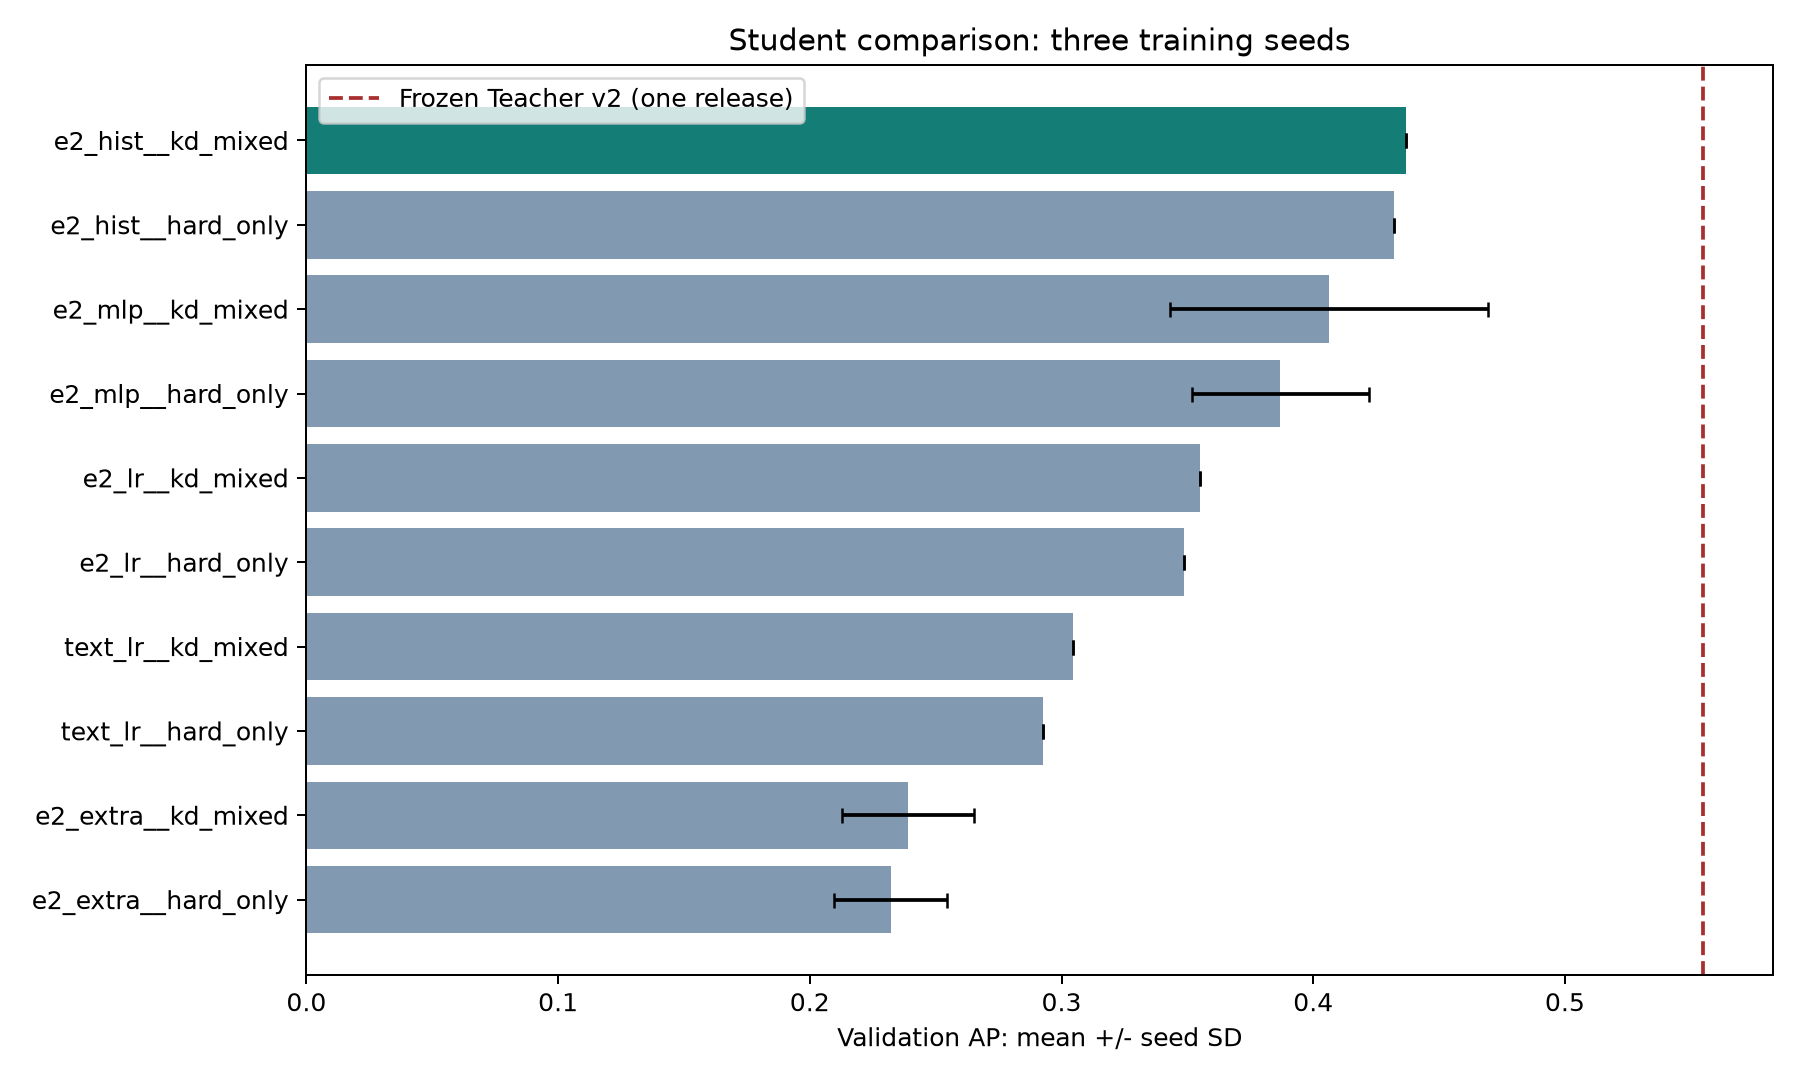

In [10]:
display(summary[["candidate", "ap_mean", "ap_sd", "recall_mean", "fpr_mean",
                 "f1_mean", "package_bytes", "p95_ms", "within_budget"]])
display(Image(filename=str(FIGURES / "ap_comparison.png")))

## 5. Cải thiện đến từ đâu?

So text LR với E2 LR để nhìn tác dụng input.
So E2 LR với HistGB hard-only để nhìn tác dụng kiến trúc.
So HistGB hard-only với HistGB KD để nhìn riêng tác dụng distillation.
Không quy toàn bộ mức tăng so với baseline cũ thành công của KD.

In [11]:
delta = pd.read_csv(TABLES / "kd_effect.csv")
display(delta)
lookup = summary.set_index("candidate")
print("Đổi input: text LR hard → E2 LR hard, ΔAP =",
      lookup.loc["e2_lr__hard_only", "ap_mean"] - lookup.loc["text_lr__hard_only", "ap_mean"])
print("Đổi kiến trúc: E2 LR hard → HistGB hard, ΔAP =",
      lookup.loc["e2_hist__hard_only", "ap_mean"] - lookup.loc["e2_lr__hard_only", "ap_mean"])
print("Thêm KD vào HistGB, ΔAP =",
      lookup.loc["e2_hist__kd_mixed", "ap_mean"] - lookup.loc["e2_hist__hard_only", "ap_mean"])

,family,hard_AP,kd_AP,kd_minus_hard_AP
0,e2_hist,0.432226,0.437032,0.004807
1,e2_mlp,0.386965,0.406203,0.019238
2,e2_lr,0.348665,0.355090,0.006425
3,text_lr,0.292578,0.304568,0.011990
4,e2_extra,0.232061,0.239060,0.006998


Đổi input: text LR hard → E2 LR hard, ΔAP = 0.056087674115460895
Đổi kiến trúc: E2 LR hard → HistGB hard, ΔAP = 0.08356054733208962
Thêm KD vào HistGB, ΔAP = 0.004806518631191525


## 6. Đồ thị và lỗi tại ngưỡng đã chọn

PR curve xem khả năng xếp hạng qua các ngưỡng. Confusion matrix xem số đúng/sai tại ngưỡng cụ thể.
Teacher giữ ngưỡng đã phát hành; Student chọn ngưỡng riêng trên Validation với FPR <= 1%.
Các đồ thị dùng seed 42 đã định trước, không phải seed tốt nhất.
Validation chỉ có 24 phishing: vài mẫu có thể làm kết quả thay đổi mạnh.

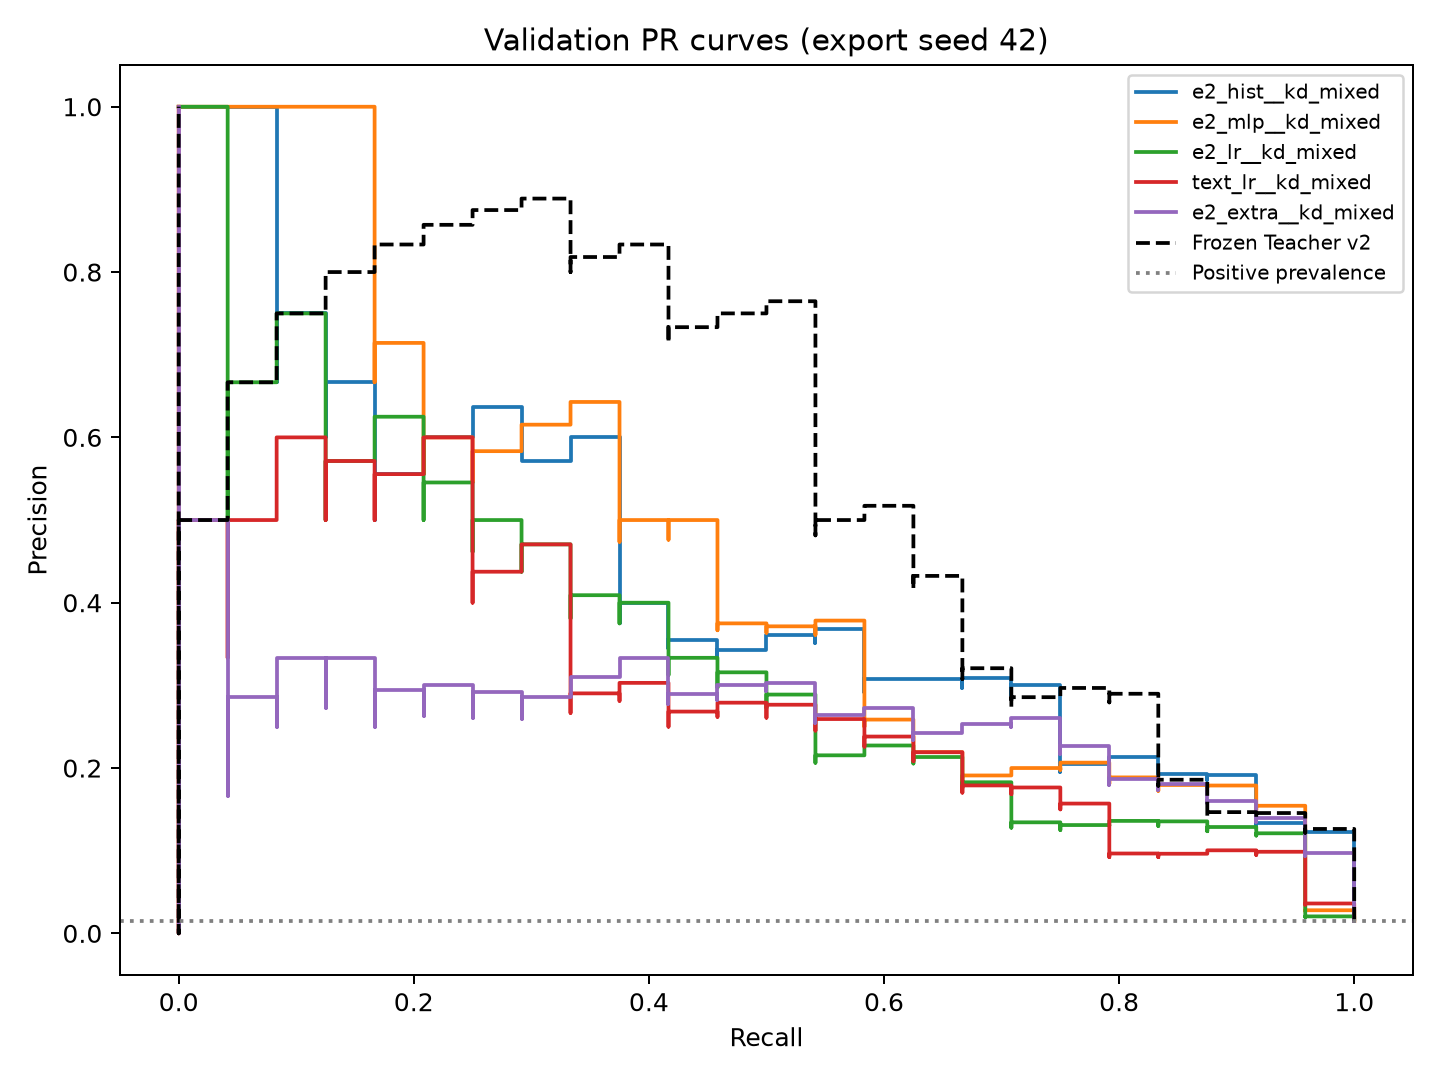

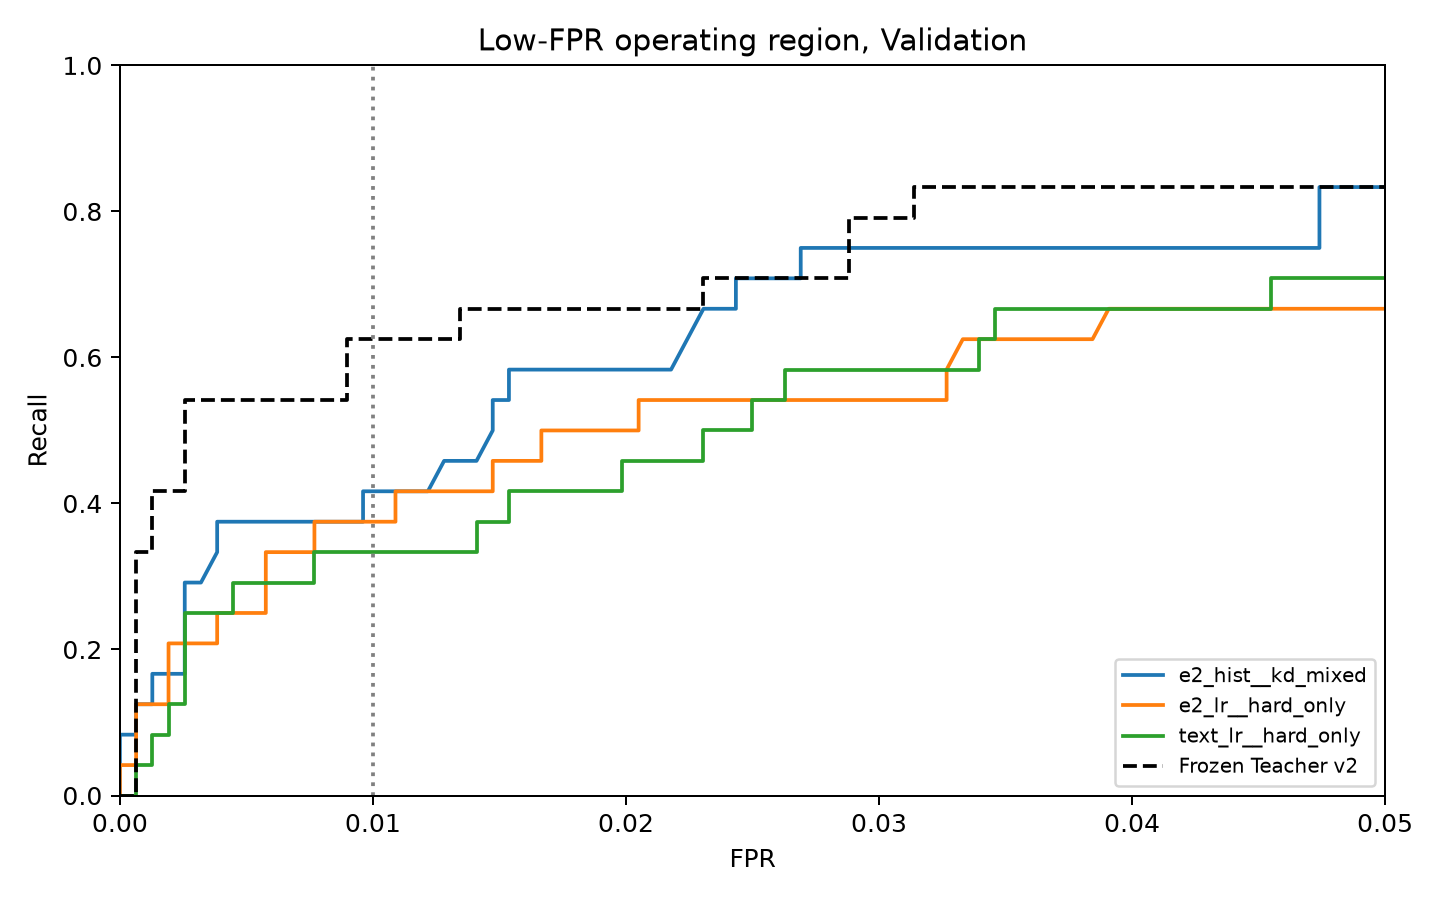

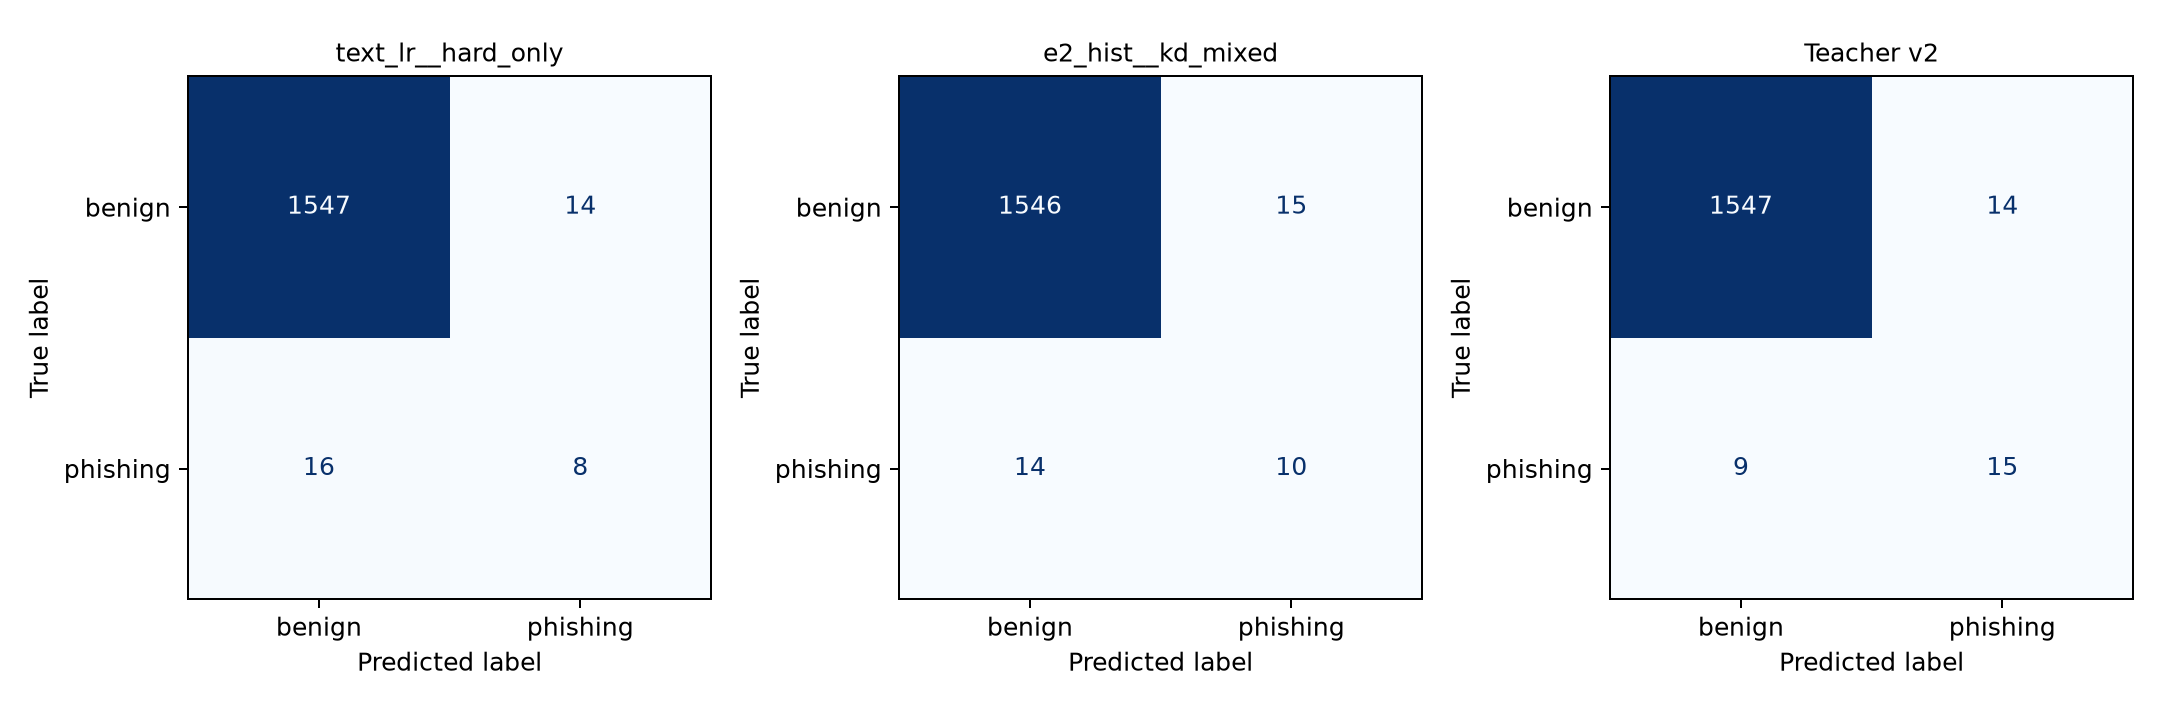

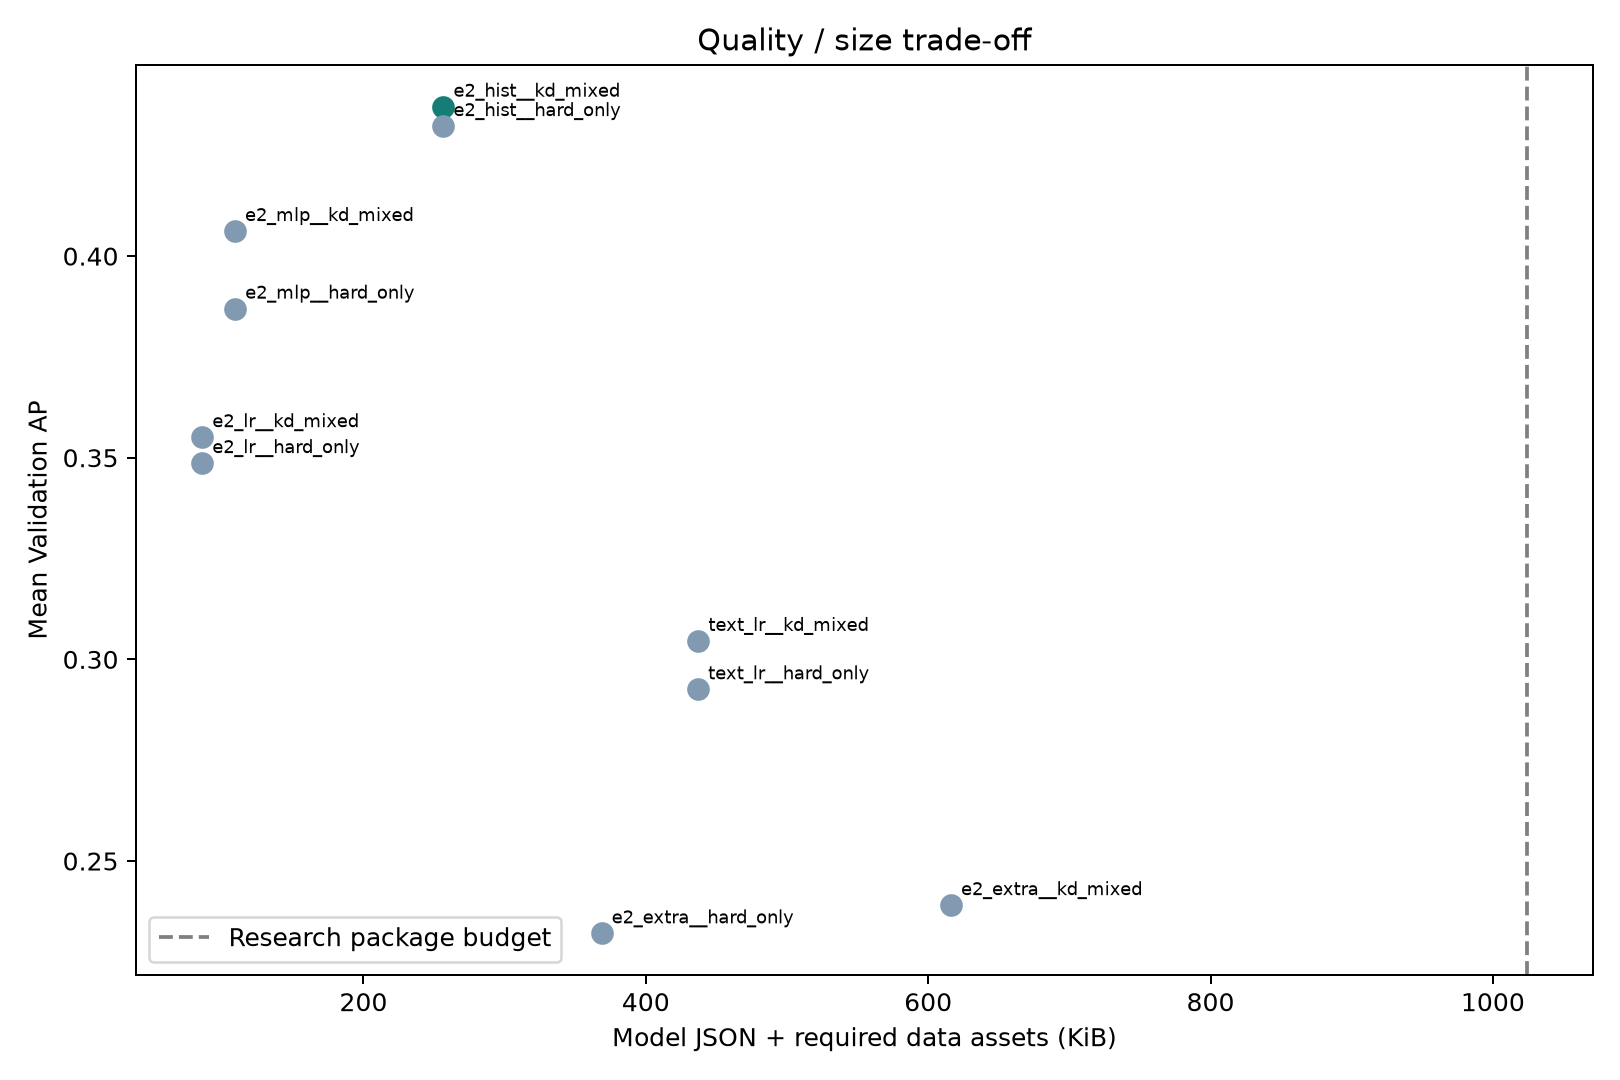

In [12]:
for filename in ["pr_curves.png", "recall_fpr.png", "confusion.png", "quality_size.png"]:
    display(Image(filename=str(FIGURES / filename)))

## 7. CI có cho thấy chắc chắn tốt hơn không?

Bootstrap theo domain Validation, paired cùng IDs, 1.000 lần.
CI là chênh lệch mean AP qua seed, có điều kiện trên các model đã fit, không điều chỉnh selection.
Nếu CI chứa 0, chưa đủ bằng chứng chắc chắn chênh lệch tổng quát là dương.
Validation đã được xem và dùng phát triển nên không phải đánh giá cuối độc lập.

In [13]:
bootstrap = pd.read_csv(TABLES / "paired_bootstrap.csv")
display(bootstrap)
print("Các CI chứa 0:", ((bootstrap.ci_low <= 0) & (bootstrap.ci_high >= 0)).all())

,candidate,comparator,delta_mean_AP,ci_low,ci_high,valid,undefined,replicates,scope
0,e2_hist__kd_mixed,e2_hist__hard_only,0.004807,-0.019927,0.025696,1000,0,1000,"conditional paired domain bootstrap, not selec..."
1,e2_hist__kd_mixed,text_lr__hard_only,0.144455,-0.108725,0.366151,1000,0,1000,"conditional paired domain bootstrap, not selec..."


Các CI chứa 0: True


## 8. Vì sao candidate được chọn, và đánh đổi gì?

Chọn mean AP cao nhất trong budget nghiên cứu 1 MiB. Export seed 42.
HistGB KD AP=0,4370 so text LR KD=0,3046; vẫn thấp hơn Teacher AP=0,5549.
Nó bắt 10/24 phishing, Teacher 15/24 ở các ngưỡng tương ứng.
E2 LR KD cũng bắt 10/24 nhưng AP thấp hơn, package nhỏ hơn: lựa chọn phụ thuộc ưu tiên chất lượng/chi phí.

MLP KD có một seed AP cao hơn HistGB, nhưng mean thấp hơn và dao động lớn.
HistGB chỉ hơn hard-only 0,0048 AP, CI chứa 0: không tuyên bố KD chắc chắn thành công.
E2 extraction chiếm phần đáng kể latency; 20 đặc trưng không đồng nghĩa inference đầu-cuối miễn phí.

In [14]:
selected = manifest["selected_candidate"]
display(summary.loc[summary.candidate.eq(selected)])
display(runs.loc[(runs.candidate == selected) & (runs.seed == 42),
                 ["candidate", "operating_point", "ap", "recall", "fpr", "tp", "fp", "tn", "fn", "threshold"]])
display(pd.read_csv(TABLES / "latency.csv"))

,candidate,family,mode,ap_mean,ap_sd,recall_mean,fpr_mean,f1_mean,agreement_mean,fit_seconds_mean,seeds,model_bytes,package_bytes,within_budget,p50_ms,p95_ms
0,e2_hist__kd_mixed,e2_hist,kd_mixed,0.437032,0.0,0.416667,0.009609,0.408163,0.976025,0.621982,3,176786,262825,True,1.0917,1.428075


,candidate,operating_point,ap,recall,fpr,tp,fp,tn,fn,threshold
42,e2_hist__kd_mixed,validation_fpr_budget,0.437032,0.416667,0.009609,10,15,1546,14,0.523207
43,e2_hist__kd_mixed,fixed_0.5,0.437032,0.458333,0.012812,11,20,1541,13,0.500000


,candidate,json_load_ms,warmup,requests,p50_ms,p95_ms,extraction_p50_ms,inference_p50_ms,scope,android_measured
0,text_lr__hard_only,7.3480,50,250,0.06300,0.115290,NaN,NaN,"desktop single URL to score, same 250 URLs, th...",False
1,text_lr__kd_mixed,7.4757,50,250,0.05920,0.089280,NaN,NaN,"desktop single URL to score, same 250 URLs, th...",False
2,e2_lr__hard_only,4.6218,50,250,0.73325,1.087125,0.71025,0.02230,"desktop single URL to score, same 250 URLs, th...",False
3,e2_lr__kd_mixed,3.5370,50,250,0.72580,0.972200,0.70350,0.02200,"desktop single URL to score, same 250 URLs, th...",False
4,e2_mlp__hard_only,3.8754,50,250,0.94415,1.818260,0.85320,0.08350,"desktop single URL to score, same 250 URLs, th...",False
5,e2_mlp__kd_mixed,4.8396,50,250,0.79865,1.064440,0.72085,0.07680,"desktop single URL to score, same 250 URLs, th...",False
6,e2_hist__hard_only,5.3501,50,250,1.10625,1.461110,0.74275,0.36180,"desktop single URL to score, same 250 URLs, th...",False
7,e2_hist__kd_mixed,5.9972,50,250,1.09170,1.428075,0.72965,0.35845,"desktop single URL to score, same 250 URLs, th...",False
8,e2_extra__hard_only,6.6892,50,250,0.91590,1.361105,0.72075,0.18845,"desktop single URL to score, same 250 URLs, th...",False
9,e2_extra__kd_mixed,9.9045,50,250,0.94645,1.581515,0.73980,0.20220,"desktop single URL to score, same 250 URLs, th...",False


## C. LightGBM theo yêu cầu nhóm — Group CV đúng ranh giới

Cấu hình mới được chốt riêng: 400 cây, 15 lá; TF-IDF 8.192 + E2.
Không chạy lại các họ khác. Phần C dùng 3 outer domain folds đã có, không trộn các số này
với Validation của phần B.

Khi kiểm tra fold C, cả Student và Teacher tạo targets chỉ được học A+B.
Các Teacher fold này đã có từ thí nghiệm trước, được kiểm ID hash/fit ledger và tái hiện OOF.
Không fit lại Teacher. Student cuối mới học targets released Teacher v2 trên toàn Train.

In [15]:
LGB_TABLES = ROOT / "reports/tables/student_lightgbm"
LGB_ART = ROOT / "artifacts/student_lightgbm"
lightgbm_manifest = json.loads((LGB_ART / "manifest.json").read_text(encoding="utf-8"))
fold_teachers = json.loads((LGB_ART / "cv_targets/manifest.json").read_text(encoding="utf-8"))
display(pd.DataFrame([
    {"fold": fold, "overlap_domains": value["domain_overlap"],
     "held_score_max_diff": value["held_prediction_parity_max_diff"],
     "Teacher_retrained": value["teacher_retrained"]}
    for fold, value in fold_teachers["folds"].items()
]))
print("CV targets: Teacher theo fold; final targets: released Teacher v2.")

,fold,overlap_domains,held_score_max_diff,Teacher_retrained
0,0,0,0.0,False
1,1,0,0.0,False
2,2,0,0.0,False


CV targets: Teacher theo fold; final targets: released Teacher v2.


### C1. Gọi LightGBM và giải thích loss

LightGBM `cross_entropy` nhận trực tiếp nhãn mềm q trong [0,1]:
loss = -q*log(p) - (1-q)*log(1-p).
Hard-only: q=y thật. KD: q=0,5*y + 0,5*Teacher score, T=1.
Cùng kiến trúc, features, seeds và 400 vòng. Không có early stopping hoặc grid.

TF-IDF được fit riêng trên fitting set mỗi fold; E2 cố định tính từ raw URL.
Constructor dưới đây đúng cấu hình train; fitting và vòng CV nằm trong
`scripts/train_lightgbm_student.py`, không tự chạy 36 fits khi mở notebook.
Ví dụ fit thực tế trong script:
```python
q = y_train if mode == "hard_only" else 0.5*y_train + 0.5*teacher_scores
model = LGBMRegressor(**config, random_state=seed)
model.fit(X_train_hybrid, q)
scores = model.predict(X_held_hybrid)
```
Teacher tạo teacher_scores cho fold đó chưa học X_held; vocabulary cũng chỉ fit X_train.


In [16]:
from lightgbm import LGBMRegressor
lgb_plan = lightgbm_manifest["plan"]
student_definition = LGBMRegressor(**lgb_plan["lightgbm"], random_state=42)
display(student_definition)
print("CV operating point cố định:", lgb_plan["cv_threshold"])
print("Các seed:", lgb_plan["seeds"], "— deterministic, không subsample; seed SD=0 không chứng minh robustness.")

,num_leaves,15
,learning_rate,0.05
,n_estimators,400
,objective,'cross_entropy'
,reg_lambda,1
,random_state,42
,n_jobs,1
,deterministic,True
,force_col_wise,True
,verbosity,-1
,boosting_type,'gbdt'


CV operating point cố định: 0.5
Các seed: [42, 43, 44] — deterministic, không subsample; seed SD=0 không chứng minh robustness.


### C2. Kết quả CV và lợi ích riêng của KD

Bảng đầu lấy mean qua 3 folds cho mỗi seed rồi tổng hợp; các seeds cho cùng kết quả.
Bảng theo fold giúp nhìn biến động dữ liệu thật, thay vì coi 9 lượt là 9 tập độc lập.
CV metrics tại threshold 0,5; không chọn threshold trên held labels của fold.

,family,mode,ap_mean,ap_seed_sd,recall_mean,fpr_mean,f1_mean,precision_mean
0,hybrid_lightgbm,hard_only,0.918412,0.0,0.761814,0.016358,0.824215,0.897766
1,hybrid_lightgbm,kd_mixed,0.918565,0.0,0.762778,0.016539,0.824380,0.896874
2,text_lr,hard_only,0.898874,0.0,0.652368,0.008997,0.767436,0.931804
3,text_lr,kd_mixed,0.897516,0.0,0.653332,0.009451,0.767045,0.928692


,mode,fold,ap,precision,recall,f1,fpr,tp,fp,tn,fn
6,hard_only,0,0.918968,0.903780,0.761216,0.826394,0.015267,526,56,3612,165
9,kd_mixed,0,0.920206,0.903114,0.755427,0.822695,0.015267,522,56,3612,169
18,hard_only,1,0.923346,0.901193,0.765557,0.827856,0.015812,529,58,3610,162
21,kd_mixed,1,0.921789,0.897306,0.771346,0.829572,0.016630,533,61,3607,158
30,hard_only,2,0.912923,0.888325,0.758671,0.818394,0.017993,525,66,3602,167
33,kd_mixed,2,0.913701,0.890203,0.761561,0.820872,0.017721,527,65,3603,165


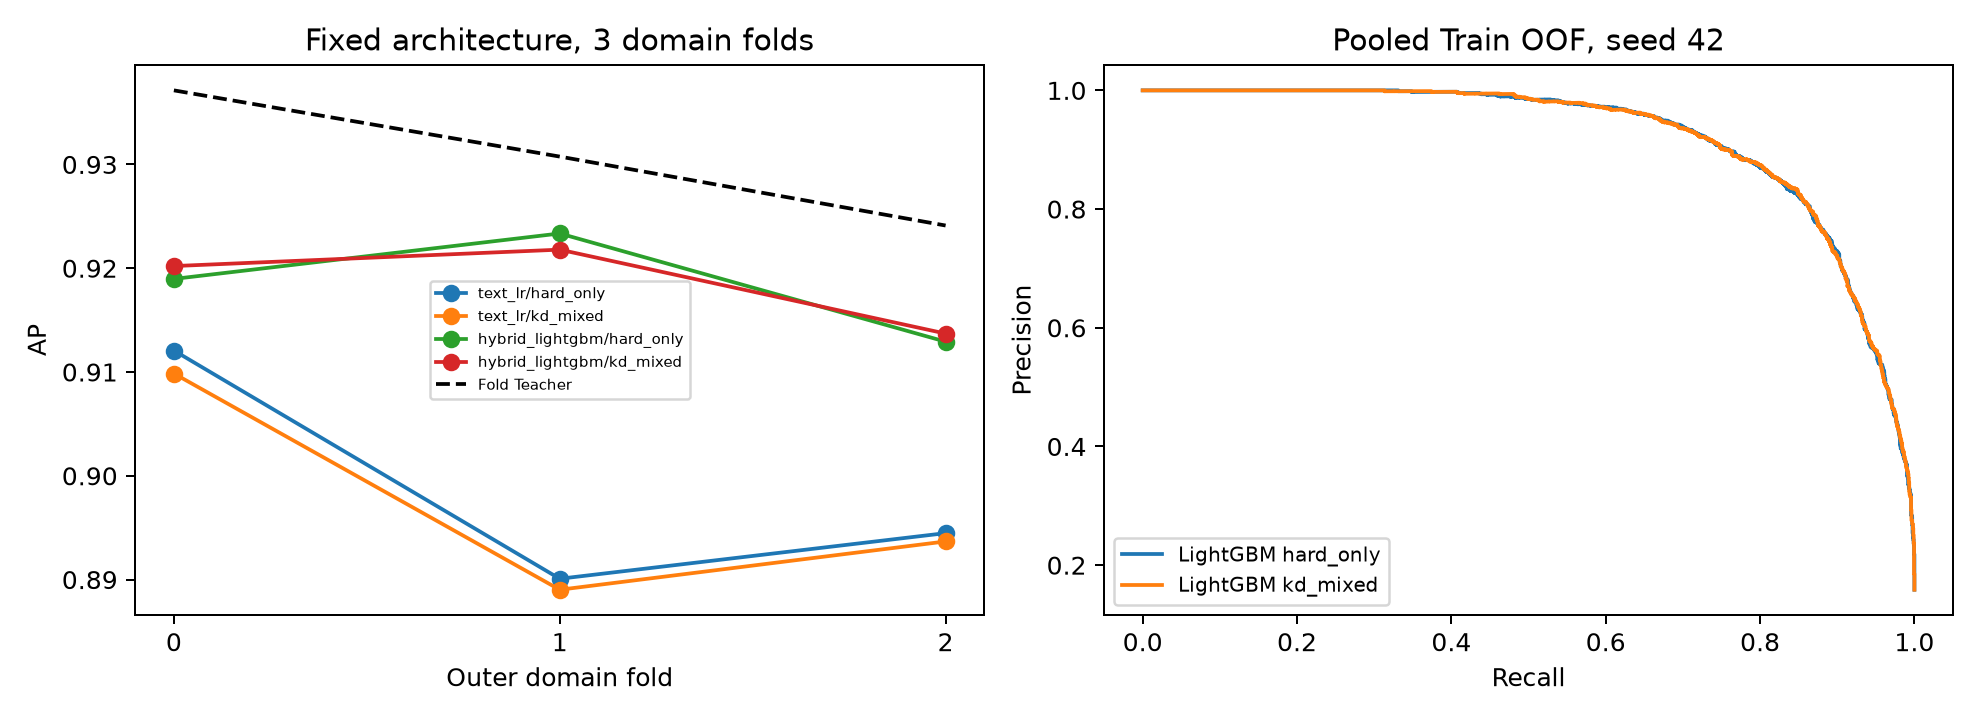

,fold,ap,precision,recall,f1,fpr,tp,fp,tn,fn,threshold
0,0,0.937135,0.908800,0.821997,0.863222,0.015540,568,57,3611,123,0.5
1,1,0.930755,0.889065,0.811867,0.848714,0.019084,561,70,3598,130,0.5
2,2,0.924113,0.898734,0.820809,0.858006,0.017448,568,64,3604,124,0.5


In [17]:
cv_summary = pd.read_csv(LGB_TABLES / "cv_summary.csv")
cv_runs = pd.read_csv(LGB_TABLES / "cv_metrics.csv")
display(cv_summary)
display(cv_runs.loc[cv_runs.family.eq("hybrid_lightgbm") & cv_runs.seed.eq(42),
                    ["mode", "fold", "ap", "precision", "recall", "f1", "fpr", "tp", "fp", "tn", "fn"]])
display(Image(filename=str(FIGURES / "lightgbm_cv.png")))
display(pd.read_csv(ROOT / "reports/tables/student_kd_analysis/fold_teacher_metrics.csv"))

In [18]:
lgb_bootstrap = json.loads((LGB_TABLES / "paired_bootstrap.json").read_text(encoding="utf-8"))
display(lgb_bootstrap)
print("CI delta KD−hard chứa 0:", lgb_bootstrap["ci_low"] <= 0 <= lgb_bootstrap["ci_high"])
print("Mean-fold ΔAP ≈ 0,000153; pooled-OOF ΔAP ≈ 0,000154, hai đại lượng hơi khác nhau.")

{'delta_mean_AP': 0.00015428956681184935,
 'ci_low': -0.0010791087621728728,
 'ci_high': 0.001340682070310864,
 'valid': 1000,
 'undefined': 0,
 'replicates': 1000,
 'scope': 'conditional paired domain bootstrap, not selection-adjusted'}

CI delta KD−hard chứa 0: True
Mean-fold ΔAP ≈ 0,000153; pooled-OOF ΔAP ≈ 0,000154, hai đại lượng hơi khác nhau.


### C3. Validation bổ sung sau khi freeze

Chọn mode bằng Train Group CV; threshold triển khai lấy từ pooled Student Train OOF
với FPR budget 1%. Đây là threshold cho model cuối, không phải outer-CV operating point.
Không dùng Validation để chọn lại mode/threshold.

LightGBM KD AP Validation=0,6549 > Teacher=0,5549. Tuy nhiên Student bắt 13/24 phishing,
Teacher 15/24; Student báo nhầm 10 benign, Teacher 14. Không có một bên thắng mọi tiêu chí.
Validation đã được xem trong đồ án, nên chưa phải independent final test.

In [19]:
validation_metrics = pd.read_csv(LGB_TABLES / "validation_metrics.csv")
display(validation_metrics.loc[validation_metrics.seed.eq(42)])
display(pd.DataFrame([json.loads((ROOT / "reports/tables/student_week7/teacher_validation.json").read_text(encoding="utf-8"))]))
display(pd.read_csv(ROOT / "reports/tables/student_kd_analysis/lightgbm_package_size.csv"))
print("Student JSON + TF-IDF/IDF + E2 reference/PSL vượt mục tiêu nghiên cứu 1 MiB.")
print("Chưa có Student Dart/Android parity, RAM/APK hoặc latency trên thiết bị.")
display(pd.read_csv(ROOT / "reports/tables/student_kd_analysis/lightgbm_desktop_latency.csv"))
print("Teacher dùng sklearn, Student dùng Python JSON; đây là implementation timing, không phải Android speedup.")

,mode,seed,ap,precision,recall,f1,fpr,tp,fp,tn,fn,threshold
0,hard_only,42,0.622327,0.565217,0.541667,0.553191,0.006406,13,10,1551,11,0.615718
3,kd_mixed,42,0.654900,0.565217,0.541667,0.553191,0.006406,13,10,1551,11,0.620450


,candidate,ap,precision,recall,f1,fpr,tp,fp,tn,fn,threshold
0,released_teacher_v2,0.55491,0.517241,0.625,0.566038,0.008969,15,14,1547,9,0.694574


,mode,package_bytes,original_goal_bytes,within_original_goal
0,hard_only,1248939,1048576,False
1,kd_mixed,1249389,1048576,False


Student JSON + TF-IDF/IDF + E2 reference/PSL vượt mục tiêu nghiên cứu 1 MiB.
Chưa có Student Dart/Android parity, RAM/APK hoặc latency trên thiết bị.


,model,backend,warmup,requests,p50_ms,p95_ms,scope,android_measured
0,Teacher v2,Python released sklearn,50,250,5.27360,7.848580,desktop raw URL to result; same 250 inputs; th...,False
1,hard_only,Python portable JSON,50,250,4.98580,6.204585,desktop raw URL to result; same 250 inputs; th...,False
2,kd_mixed,Python portable JSON,50,250,4.97475,6.112000,desktop raw URL to result; same 250 inputs; th...,False


Teacher dùng sklearn, Student dùng Python JSON; đây là implementation timing, không phải Android speedup.


### C4. Artifact và Python reference

Gói gồm model JSON/native, vocabulary/IDF, reference/PSL, threshold, hashes và fixture.
LightGBM không gọi Teacher/API khi suy luận. Phiên bản JSON Python chỉ là reference
để Hy port Dart. Các fixture không có ground truth accuracy labels.

In [20]:
from phishguard_vn.student_lightgbm import load_lightgbm_student
lgb_student = load_lightgbm_student(ROOT)
display(lgb_student.predict_one("https://EXAMPLE.com/Login?Q=%2F"))
display(lightgbm_manifest["packaging_only"])
print("Teacher engine vẫn là:",
      json.loads((ROOT / "configs/teacher_lock.json").read_text(encoding="utf-8"))["model_version"])

{'score': 0.7437445834210804,
 'score_kind': 'uncalibrated_sigmoid',
 'calibrated': False,
 'label': 'phishing',
 'class_id': 1,
 'threshold': 0.6204500086017339,
 'model_version': 'lightgbm-student-kd_mixed',
 'release_status': 'experimental',
 'android_verified': False}

{'script': 'scripts/summarize_student_comparison.py',
 'script_sha256': '080994b8719b8629f3e18dd573e8a54477391025d1251ccb3bc9aec5bce370cf',
 'training_rerun': False,
 'valid_reference_cases': 52,
 'rejected_reference_cases': 6}

Teacher engine vẫn là: teacher-stacking-v2


## D. Rà soát KD: biết gì, chưa biết gì?

Đã tách tác dụng input, thuật toán và KD; kiểm target lineage, seeds, AP/operating points,
confidence intervals, size và chi phí desktop ở khảo sát ban đầu. LightGBM bổ sung Group CV
với Teacher không thấy held fold, hai mode matched và đầy đủ export/parity Python.

Teacher targets trên Train khá sát hard labels. Trộn alpha=0,5 thường chỉ làm đổi mục tiêu
học một ít; đây là **giả thuyết** giải thích KD yếu, không phải nguyên nhân đã được chứng minh.
Train có 15,86% phishing, Validation 1,51%; không so AP khác cohort như cùng điều kiện.
Score Teacher chưa calibrated, Teacher–Student co-error không chứng minh quan hệ nhân quả.

In [21]:
AUDIT = ROOT / "reports/tables/student_kd_analysis"
display(pd.read_csv(AUDIT / "teacher_targets_by_label.csv"))
display(pd.read_csv(AUDIT / "cv_teacher_targets_by_label.csv"))
display(pd.read_csv(AUDIT / "hard_kd_decision_changes.csv"))
display(pd.read_csv(AUDIT / "teacher_student_errors.csv"))
print("Ở operating points đã freeze: LightGBM hard và KD cho cùng nhãn trên toàn Validation.")

,split,label,n,positive_prevalence,teacher_score_mean,teacher_score_p10,teacher_score_p50,teacher_score_p90,teacher_label_agreement,mean_distance_from_hard_label
0,Train (in-sample Teacher),0,11004,0.158587,0.017749,0.000986,0.006515,0.037572,0.999636,0.017749
1,Train (in-sample Teacher),1,2074,0.158587,0.934262,0.808382,0.982247,0.998280,0.949373,0.065738
2,Validation (development),0,1561,0.015142,0.050707,0.001209,0.012129,0.116500,0.991031,0.050707
3,Validation (development),1,24,0.015142,0.690983,0.165305,0.897898,0.981320,0.625000,0.309017


,outer_fold,label,n,mean_teacher_score,mean_kd_target,mean_teacher_distance_from_label
0,0,0,7336,0.021213,0.010607,0.021213
1,0,1,1383,0.925055,0.962527,0.074945
2,1,0,7336,0.018705,0.009352,0.018705
3,1,1,1383,0.937099,0.968549,0.062901
4,2,0,7336,0.017293,0.008647,0.017293
5,2,1,1382,0.937818,0.968909,0.062182


,label,change,n
0,0,improved,0
1,0,worsened,0
2,0,unchanged,1561
3,1,improved,0
4,1,worsened,0
5,1,unchanged,24


,label,teacher_correct,student_correct,n
0,0,False,False,5
1,0,False,True,9
2,0,True,False,5
3,0,True,True,1542
4,1,False,False,6
5,1,False,True,3
6,1,True,False,5
7,1,True,True,10


Ở operating points đã freeze: LightGBM hard và KD cho cùng nhãn trên toàn Validation.


### Các hướng chưa thử

Không được kết luận KD vô ích nói chung. Bảng dưới chỉ là các hướng còn mở, không phải
kế hoạch tự động chạy tiếp. Không dùng Official Test hoặc Validation đã xem để cứu một
candidate. Cross-fit targets nội bộ khác với chỉ có outer Teacher: hiện chưa làm phần đó.
MLP cũ chạy đủ 200 epochs nhưng chưa hội tụ, nên không chứng minh đã tối ưu hết họ MLP.

In [22]:
display(pd.read_csv(AUDIT / "untested_directions.csv"))
display(pd.read_csv(AUDIT / "mlp_optimization.csv")[["candidate", "seed", "iterations", "warning_count"]])

,direction,not_run,status
0,Tỷ lệ học Teacher,"Hiện chỉ alpha=0 (hard baseline) và 0,5; chưa ...",Chưa thử; không tune tiếp trên Validation đã xem.
1,Dạng target/loss,"Hard Teacher labels, logit matching, temperatu...",Chưa thử; không gọi hard_only hiện tại là học ...
2,Độ tin cậy Teacher,"Calibration, phân tích hoặc giảm trọng số các ...","Chưa thử; raw score hiện tại chưa calibrated, ..."
3,Tạo targets,Teacher targets cross-fit theo domain trong Tr...,"Chưa thử; cần thiết kế nghiên cứu riêng, không..."
4,Kiến trúc/đầu vào,"Char-CNN, MLP đọc text/raw bytes, distillation...",Chưa thử các hướng này; hybrid TF-IDF+E2 đã th...
5,Optimization/imbalance,"MLP train dài hơn/cấu hình khác, class weighti...",Chưa thử; fixed-budget 200 epochs không đồng n...
6,Dữ liệu/đánh giá,"Nhãn được kiểm chứng thêm, cohort độc lập nhiề...",Chưa có; không dùng Official Test để lựa chọn ...
7,Triển khai/nén,Benchmark Android Teacher/Student; quantizatio...,Chưa làm trong nghiên cứu này; quantization/pr...


,candidate,seed,iterations,warning_count
0,e2_mlp__hard_only,42,200,1
1,e2_mlp__hard_only,43,200,1
2,e2_mlp__hard_only,44,200,1
3,e2_mlp__kd_mixed,42,200,1
4,e2_mlp__kd_mixed,43,200,1
5,e2_mlp__kd_mixed,44,200,1


## E. Kết luận của nhóm và bàn giao

**Giữ Teacher stacking v2 làm engine tích hợp Android.** Đây là quyết định cho đồ án hiện tại,
không phải kết luận mọi Student đều kém: LightGBM có AP Validation cao hơn nhưng Teacher
fold-CV cao hơn, KD tăng rất ít trong CV, và lợi ích chi phí Android của Student chưa được đo.

Giữ toàn bộ Student artifacts/kết quả để báo cáo trung thực. Không tự promote Student,
không sửa Teacher/threshold/E2/reference/splits, không chấm Official Test/external.
Hy ưu tiên Teacher UI/offline/device benchmark; LightGBM bundle sẵn để thử riêng khi nhóm cần.
Khiêm kiểm hashes, input lỗi, regression và Python–Dart parity trước khi nghiệm thu.
Bản Python/fixture khớp không phải bằng chứng Android đã chạy đúng hoặc production-ready.

Đọc: `reports/week7_student_comparison.md`,
`docs/week7_lightgbm_protocol.md`, `docs/week7_lightgbm_handoff.md`.
Notebook này gộp toàn bộ câu chuyện, không có notebook baseline/thử nghiệm riêng nữa.